In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score,confusion_matrix,ConfusionMatrixDisplay,classification_report)
from google.colab import files
uploaded = files.upload()

Saving X_test.csv to X_test (1).csv
Saving X_train.csv to X_train (1).csv
Saving y_test.csv to y_test (1).csv
Saving y_train.csv to y_train (1).csv


In [3]:
X_train = pd.read_csv("X_train.csv")
X_test = pd.read_csv("X_test.csv")
y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()
print("Training and testing datasets loaded successfully!")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Training and testing datasets loaded successfully!
X_train shape: (5634, 30)
X_test shape: (1409, 30)
y_train shape: (5634,)
y_test shape: (1409,)


In [4]:
log_model = LogisticRegression(max_iter=1000,random_state=42)
log_model.fit(X_train, y_train)
print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [5]:
tree_model = DecisionTreeClassifier(random_state=42,max_depth=5)
tree_model.fit(X_train, y_train)
print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [9]:
log_predictions = log_model.predict(X_test)
tree_predictions = tree_model.predict(X_test)
print("Logistic Regression:", log_predictions[:10])
print("Decision Tree:", tree_predictions[:10])
print("Actual values:", y_test.iloc[:10].values)
log_accuracy = accuracy_score(y_test, log_predictions)
tree_accuracy = accuracy_score(y_test, tree_predictions)
print("Logistic Regression Accuracy:",round(log_accuracy * 100, 2), "%")
print("Decision Tree Accuracy:",round(tree_accuracy * 100, 2), "%")
results = pd.DataFrame({"Model": ["Logistic Regression","Decision Tree"],"Accuracy": [log_accuracy * 100,tree_accuracy * 100]})
print(results)

Logistic Regression: [0 1 0 0 0 1 0 0 0 0]
Decision Tree: [0 1 0 0 0 0 0 0 0 0]
Actual values: [0 0 0 0 0 0 0 0 0 1]
Logistic Regression Accuracy: 80.7 %
Decision Tree Accuracy: 79.42 %
                 Model   Accuracy
0  Logistic Regression  80.695529
1        Decision Tree  79.418027


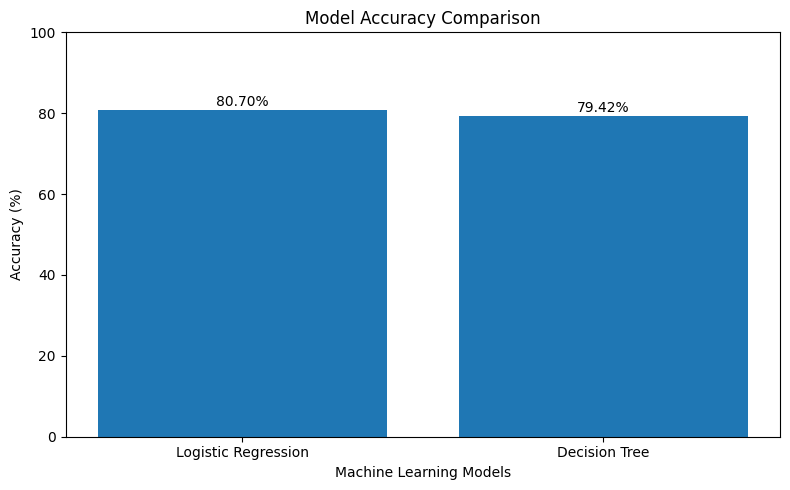

In [10]:
plt.figure(figsize=(8, 5))
plt.bar(results["Model"],results["Accuracy"])
plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)
for i, value in enumerate(results["Accuracy"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")
plt.tight_layout()
plt.savefig("accuracy_comparison.png", dpi=300)
plt.show()

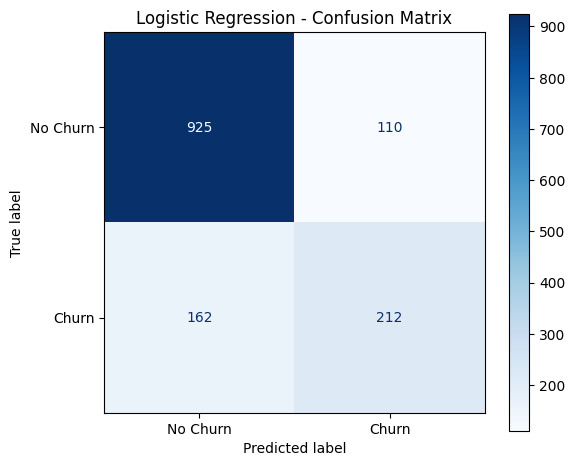

In [11]:
log_cm = confusion_matrix(y_test,log_predictions,labels=[0, 1])
log_display = ConfusionMatrixDisplay(confusion_matrix=log_cm,display_labels=["No Churn", "Churn"])
fig, ax = plt.subplots(figsize=(6, 5))
log_display.plot(cmap="Blues",ax=ax,values_format="d")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig("logistic_confusion_matrix.png", dpi=300)
plt.show()

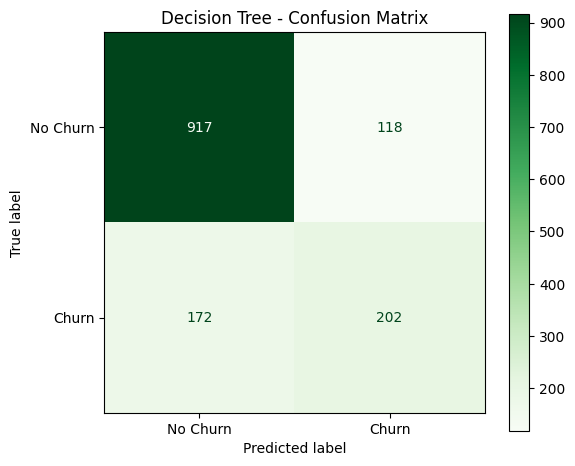

In [12]:
tree_cm = confusion_matrix(y_test,tree_predictions,labels=[0, 1])
tree_display = ConfusionMatrixDisplay(confusion_matrix=tree_cm,display_labels=["No Churn", "Churn"])
fig, ax = plt.subplots(figsize=(6, 5))
tree_display.plot(cmap="Greens",ax=ax,values_format="d")
plt.title("Decision Tree - Confusion Matrix")
plt.tight_layout()
plt.savefig("decision_tree_confusion_matrix.png", dpi=300)
plt.show()

In [13]:
print("LOGISTIC REGRESSION REPORT")
print(classification_report(y_test,log_predictions,target_names=["No Churn", "Churn"]))
print("\nDECISION TREE REPORT")
print(classification_report(y_test,tree_predictions,target_names=["No Churn", "Churn"]))

LOGISTIC REGRESSION REPORT
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


DECISION TREE REPORT
              precision    recall  f1-score   support

    No Churn       0.84      0.89      0.86      1035
       Churn       0.63      0.54      0.58       374

    accuracy                           0.79      1409
   macro avg       0.74      0.71      0.72      1409
weighted avg       0.79      0.79      0.79      1409



In [14]:
if log_accuracy > tree_accuracy:
    print("Logistic Regression performed better.")
    print("Selected Model: Logistic Regression")

elif tree_accuracy > log_accuracy:
    print("Decision Tree performed better.")
    print("Selected Model: Decision Tree")

else:
    print("Both models achieved the same accuracy.")

Logistic Regression performed better.
Selected Model: Logistic Regression
